## Inference_Plot_Regional_Landcover

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
import geopandas as gpd
import time
import pickle
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.patches as mpatches

import random
from torch.utils.data import * 

## Map Year, Region, Model

In [38]:
year = '2018'
#region_name = 'biomeF'
#region_name = 'biomeAll_southern_africa'
#region_name = 'biomeAll_eastern_sahel'
region_name = 'biomeAll_western_usa'
model_name = 'All'  

In [39]:
# filename1
filename1 = '../Inference_Points/' + region_name + '_model' + model_name + '_pred_index_' + year + '.npy'
print(filename1)

../Inference_Points/biomeAll_western_usa_modelAll_pred_index_2018.npy


In [40]:
# load predicted index data
pred_index = np.load(filename1)
print(pred_index.shape)

(37789,)


In [ ]:
class_names = ['Water(0)','Developed(1)','Barren(2)','Trees(3)','Shrub(4)','Grassland(5)', 'Agriculture(6)'] 

## Import Point Locations

In [41]:
#points = gpd.read_parquet("../Inference_Points/biomeA_random_points.parquet")  
#points = gpd.read_parquet("../Inference_Points/biomeAll_southern_africa_random_points.parquet")  
#points = gpd.read_parquet("../Inference_Points/biomeAll_eastern_sahel_random_points.parquet") 
points = gpd.read_parquet("../Inference_Points/biomeAll_western_usa_random_points.parquet")  

len(points)

37789

In [42]:
# add lon and lat columns
points['lon'] = points.geometry.x
points['lat'] = points.geometry.y

points.head(5)

,geometry,lon,lat
0,POINT (-116.78916 34.38031),-116.789158,34.380307
1,POINT (-96.88028 28.41738),-96.880280,28.417383
2,POINT (-108.5843 37.1032),-108.584296,37.103200
3,POINT (-117.25963 35.27312),-117.259632,35.273118
4,POINT (-110.89336 38.29898),-110.893358,38.298980


## Add Predicted Index to Points Locations

In [43]:
points["index"] = pred_index[:]

In [44]:
points.head()

,geometry,lon,lat,index
0,POINT (-116.78916 34.38031),-116.789158,34.380307,4
1,POINT (-96.88028 28.41738),-96.880280,28.417383,5
2,POINT (-108.5843 37.1032),-108.584296,37.103200,3
3,POINT (-117.25963 35.27312),-117.259632,35.273118,4
4,POINT (-110.89336 38.29898),-110.893358,38.298980,2


## Add a color column

In [45]:
color_map = {
    0: "lightblue",              # water
    1: "red",                    # developed
    2: "yellow",                  # barren
    3: "darkgreen",              # trees
    4: "orange",                 # shrub
    5: "lightgreen",             # grass
    6: "#FF10F0"                    # agriculture
}

points["color"] = points["index"].map(color_map)

In [46]:
points.head()

,geometry,lon,lat,index,color
0,POINT (-116.78916 34.38031),-116.789158,34.380307,4,orange
1,POINT (-96.88028 28.41738),-96.880280,28.417383,5,lightgreen
2,POINT (-108.5843 37.1032),-108.584296,37.103200,3,darkgreen
3,POINT (-117.25963 35.27312),-117.259632,35.273118,4,orange
4,POINT (-110.89336 38.29898),-110.893358,38.298980,2,yellow


## Plot Landcover points

In [47]:
gdf_countries = gpd.read_parquet('../Shapefiles/ne_10m_admin_0_countries.parquet')

In [48]:
gdf_us_states = gpd.read_file("../Shapefiles/ne_50m_admin_1_states_provinces_lines.shp")    

In [49]:
gdf_biomeA = gpd.read_parquet('../WWF_TEOW/Biome_Shapefiles/BiomeA.parquet')     # A. Tropical and Subtropical Dry Broadleaf Forests 
gdf_biomeB = gpd.read_parquet('../WWF_TEOW/Biome_Shapefiles/BiomeB.parquet')     # B. Tropical and Subtropical Grasslands, Savannas, and Shrublands 
gdf_biomeC = gpd.read_parquet('../WWF_TEOW/Biome_Shapefiles/BiomeC.parquet')     # C. Temperate Grasslands, Savannas, and Shrublands 
gdf_biomeD = gpd.read_parquet('../WWF_TEOW/Biome_Shapefiles/BiomeD.parquet')    # D. Montane Grasslands and Shrublands 
gdf_biomeE = gpd.read_parquet('../WWF_TEOW/Biome_Shapefiles/BiomeE.parquet')    # E. Mediterranean Forests, Woodlands, and Scrub 
gdf_biomeF = gpd.read_parquet('../WWF_TEOW/Biome_Shapefiles/BiomeF.parquet')    # F. Deserts and Xeric Shrublands 

In [50]:
# Read clipped biome polygons
#gdf_biomeAll = gpd.read_parquet('../WWF_TEOW/biomeAll_southern_africa.parquet')
gdf_biomeAll = gpd.read_parquet('../WWF_TEOW/biomeAll_western_usa.parquet')
len(gdf_biomeAll)

1

In [51]:
#plot_name = "../Inference_Change/southern_africa_landcover_2018.jpg"
#plot_name = "../Inference_Change/eastern_sahel_landcover_2018.jpg"
#plot_name = "../Inference_Change/eastern_sahel_landcover_2025.jpg"
plot_name = "../Inference_Change/western_usa_landcover_2018.jpg"

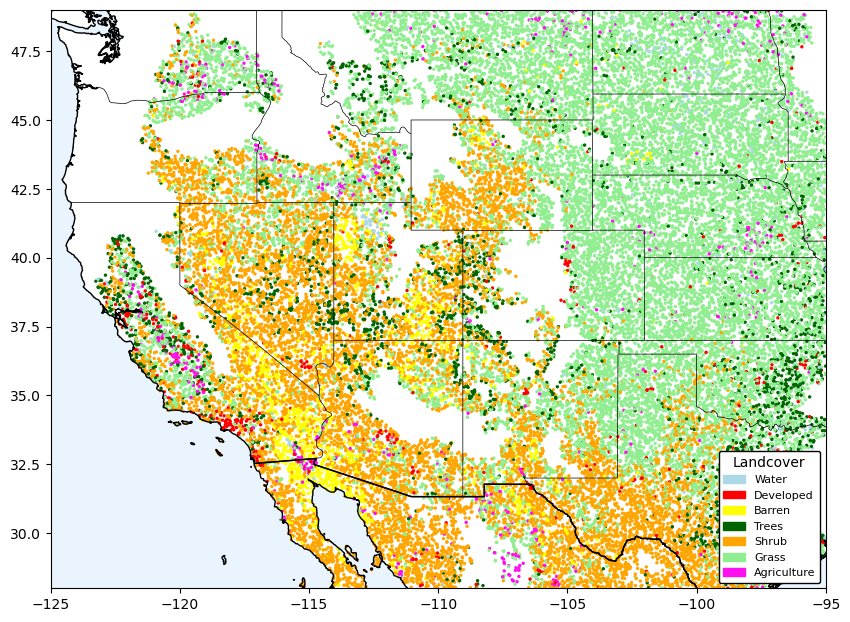

In [52]:
fig, ax = plt.subplots(figsize=(10, 8))
ax.set_facecolor('#EAF4FF')

#ax.set_title('Dryland Biomes', fontsize=10)

# global
#ax.set_xlim([-160, 160])
#ax.set_ylim([-80, 80])

# usa only
ax.set_xlim([-125, -95])
ax.set_ylim([28, 49])

# southern africa only
#ax.set_xlim([12, 37])
#ax.set_ylim([-35, -20])

# eastern Sahel
#ax.set_xlim([10, 35])
#ax.set_ylim([5, 25])

# Remove tick marks and labels
#ax.set_xticks([])
#ax.set_yticks([])
#ax.set_xticklabels([])
#ax.set_yticklabels([])


gdf_countries.plot(ax=ax, color= 'white', edgecolor='none')

points.plot(
    ax=ax,
    color=points["color"],
    markersize=6,
    legend=True,
    edgecolor="none"
)

gdf_countries.plot(ax=ax, color= 'none', edgecolor='black',linewidth=1)

# Create custom legend handles
water_pt = mpatches.Patch(color="lightblue", label="Water")
dev_pt = mpatches.Patch(color="red", label="Developed")
barren_pt = mpatches.Patch(color="yellow", label="Barren")
trees_pt = mpatches.Patch(color="darkgreen", label="Trees")
shrub_pt = mpatches.Patch(color="orange", label="Shrub")
grass_pt = mpatches.Patch(color="lightgreen", label="Grass")
ag_pt = mpatches.Patch(color="#FF10F0", label="Agriculture")   # pink

gdf_us_states.plot(ax=ax, color= 'black', edgecolor='black', linewidth = 0.5)

leg=ax.legend(handles=[water_pt, dev_pt, barren_pt, trees_pt, shrub_pt, grass_pt, ag_pt],
          loc="lower right",
          fontsize=8,
          frameon=True,
          framealpha=1.0,
          title="Landcover"
         )
leg.get_frame().set_edgecolor('black')

plt.savefig(plot_name, dpi=300, bbox_inches="tight")
plt.show()

## Plot Change

In [53]:
year1 = '2018'
year2 = '2025'
#region_name = 'biomeF'
#region_name = 'biomeAll_southern_africa'
#region_name = 'biomeAll_eastern_sahel'
region_name = 'biomeAll_western_usa'
model_name = 'All'  

In [54]:
# filename1
filename1 = '../Inference_Points/' + region_name + '_model' + model_name + '_pred_index_' + year1 + '.npy'
print(filename1)

# filename2
filename2 = '../Inference_Points/' + region_name + '_model' + model_name + '_pred_index_' + year2 + '.npy'
print(filename2)

../Inference_Points/biomeAll_western_usa_modelAll_pred_index_2018.npy
../Inference_Points/biomeAll_western_usa_modelAll_pred_index_2025.npy


In [55]:
# load predicted index data
pred_index1 = np.load(filename1)
print(pred_index1.shape)

pred_index2 = np.load(filename2)
print(pred_index2.shape)

(37789,)
(37789,)


In [56]:
# concatenate
change = np.column_stack((pred_index1, pred_index2))
change.shape

(37789, 2)

In [57]:
# add a third column of zeros
zero_col = np.zeros((change.shape[0], 1), dtype=int)
change = np.hstack((change, zero_col))

In [58]:
change.shape

(37789, 3)

In [59]:
class_names = ['Water(0)','Developed(1)','Barren(2)','Trees(3)','Shrub(4)','Grassland(5)', 'Agriculture(6)'] 

### Add Tree index | 0 - no Trees | 1 - Tree lose | 2 - no change | 3 - Tree increase

In [60]:
#class_index = 3   # trees
class_index = 2    # barren
#class_index = 5   # grass
#class_index = 6   # agriculture

In [61]:
# mask returns True or False for all rows - vectories
mask = (change[:, 0] == class_index) & (change[:, 1] != class_index)  # lose
change[mask, 2] = 1

mask = (change[:, 0] == class_index) & (change[:, 1] == class_index)  # no change 
change[mask, 2] = 2

mask = (change[:, 0] != class_index) & (change[:, 1] == class_index)  # gain
change[mask, 2] = 3

In [62]:
change[:10]

array([[4, 4, 0],
       [5, 3, 0],
       [3, 4, 0],
       [4, 5, 0],
       [2, 2, 2],
       [4, 4, 0],
       [4, 4, 0],
       [5, 5, 0],
       [4, 4, 0],
       [5, 3, 0]], dtype=int64)

### Import Point Locations

In [63]:
#points = gpd.read_parquet("../Inference_Points/biomeA_random_points.parquet") 
#points = gpd.read_parquet("../Inference_Points/biomeAll_southern_africa_random_points.parquet") 
#points = gpd.read_parquet("../Inference_Points/biomeAll_eastern_sahel_random_points.parquet")  
points = gpd.read_parquet("../Inference_Points/biomeAll_western_usa_random_points.parquet")  
 
len(points)

37789

In [64]:
# add lon and lat columns
points['lon'] = points.geometry.x
points['lat'] = points.geometry.y

points.head(5)

,geometry,lon,lat
0,POINT (-116.78916 34.38031),-116.789158,34.380307
1,POINT (-96.88028 28.41738),-96.880280,28.417383
2,POINT (-108.5843 37.1032),-108.584296,37.103200
3,POINT (-117.25963 35.27312),-117.259632,35.273118
4,POINT (-110.89336 38.29898),-110.893358,38.298980


### Add Change Index to Points Locations

In [65]:
points["change"] = change[:,2]
points.head()

,geometry,lon,lat,change
0,POINT (-116.78916 34.38031),-116.789158,34.380307,0
1,POINT (-96.88028 28.41738),-96.880280,28.417383,0
2,POINT (-108.5843 37.1032),-108.584296,37.103200,0
3,POINT (-117.25963 35.27312),-117.259632,35.273118,0
4,POINT (-110.89336 38.29898),-110.893358,38.298980,2


### Add a color column

In [66]:
color_map = {
    0: "lightgrey",               # no trees
    1: "blue",                    # decrease
    2: "#FFFACD",                 # no change
    3: "red"                      # increase
}

points["color"] = points["change"].map(color_map)

In [67]:
points.head()

,geometry,lon,lat,change,color
0,POINT (-116.78916 34.38031),-116.789158,34.380307,0,lightgrey
1,POINT (-96.88028 28.41738),-96.880280,28.417383,0,lightgrey
2,POINT (-108.5843 37.1032),-108.584296,37.103200,0,lightgrey
3,POINT (-117.25963 35.27312),-117.259632,35.273118,0,lightgrey
4,POINT (-110.89336 38.29898),-110.893358,38.298980,2,#FFFACD


## Plot change points

In [ ]:
gdf_countries = gpd.read_parquet('../Shapefiles/ne_10m_admin_0_countries.parquet')

In [69]:
#plot_name = "../Inference_Change/biomeAll_southern_africa_Agriculture.jpg"
#plot_name = "../Inference_Change/biomeAll_southern_africa_Grass.jpg"

#plot_name = "../Inference_Change/biomeAll_eastern_sahel_Trees.jpg"
#plot_name = "../Inference_Change/biomeAll_eastern_sahel_Grass.jpg"

plot_name = "../Inference_Change/biomeAll_western_usa_Barren.jpg"

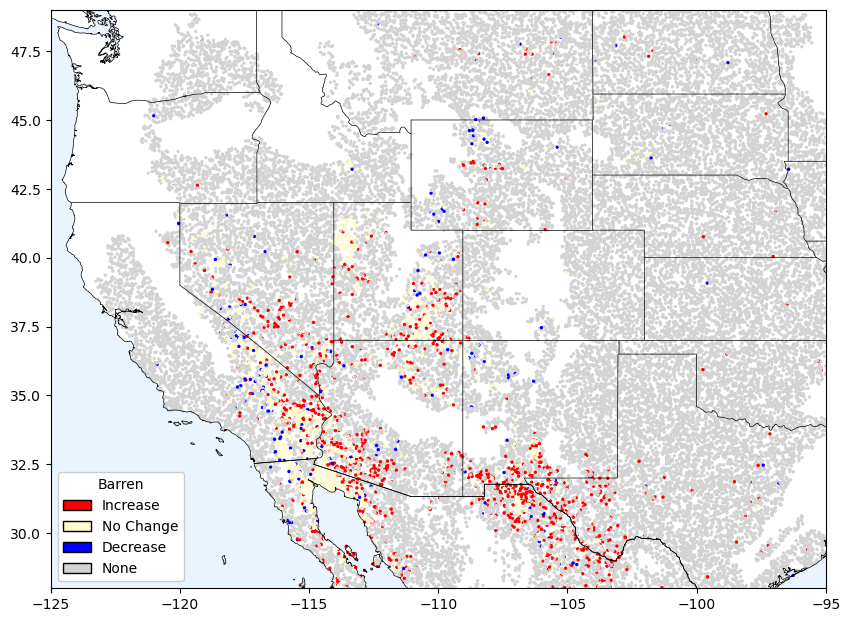

In [71]:
fig, ax = plt.subplots(figsize=(10, 8))
ax.set_facecolor('#EAF4FF')

# global
#ax.set_xlim([-160, 160])
#ax.set_ylim([-80, 80])

# usa only
ax.set_xlim([-125, -95])
ax.set_ylim([28, 49])

# southern africa only
#ax.set_xlim([12, 37])
#ax.set_ylim([-35, -20])

# eastern Sahel
#ax.set_xlim([10, 35])
#ax.set_ylim([5, 25])

# Remove tick marks and labels
#ax.set_xticks([])
#ax.set_yticks([])
#ax.set_xticklabels([])
#ax.set_yticklabels([])

gdf_countries.plot(ax=ax, color= 'white', edgecolor='none')

points.plot(
    ax=ax,
    color=points["color"],
    markersize=6,
    legend=True,
    edgecolor="none"
)
gdf_countries.plot(ax=ax, color= 'none', edgecolor='black',linewidth=0.5)

# Create custom legend handles
red_patch = mpatches.Patch(facecolor="red", edgecolor="black", linewidth=1, label="Increase")
#green_patch = mpatches.Patch(facecolor="#AAF0D1", edgecolor="black", linewidth=1,label="No Change")
green_patch = mpatches.Patch(facecolor="#FFFACD", edgecolor="black", linewidth=1,label="No Change")
blue_patch = mpatches.Patch(facecolor="blue", edgecolor="black", linewidth=1,label="Decrease")
grey_patch = mpatches.Patch(facecolor="lightgrey", edgecolor="black", linewidth=1,label="None")

gdf_us_states.plot(ax=ax, color= 'black', edgecolor='black', linewidth = 0.5)

ax.legend(handles=[red_patch, green_patch, blue_patch, grey_patch],
          loc="lower left",
          fontsize=10,
          frameon=True,
          framealpha=1.0,
          title="Barren"
         )


plt.savefig(plot_name, dpi=300, bbox_inches="tight")
plt.show()

## Plot all Biomes

In [ ]:
gdf_countries = gpd.read_parquet('../Shapefiles/ne_10m_admin_0_countries.parquet')

In [ ]:
# Plot the world map
fig, ax = plt.subplots(figsize=(10, 10))
ax.set_facecolor('#EAF4FF')

# Set limits and remove axis
#ax.set_xlim([-160, 160])
#ax.set_ylim([-80, 80])
#ax.set_axis_off()

# southern africa only
ax.set_xlim([12, 37])
ax.set_ylim([-35, -20])

# chad sudan only
#ax.set_xlim([10, 35])
#ax.set_ylim([5, 25])

#ax.set_xticks([])
#ax.set_yticks([])
#ax.set_xticklabels([])
#ax.set_yticklabels([])

gdf_countries.plot(ax=ax, color= 'grey', edgecolor='none')

gdf_biomeA.plot(ax=ax, color='darkgreen', edgecolor='none')
gdf_biomeB.plot(ax=ax, color='orange', edgecolor='none')
gdf_biomeC.plot(ax=ax, color='lightgreen', edgecolor='none')
gdf_biomeD.plot(ax=ax, color='pink', edgecolor='none')
gdf_biomeE.plot(ax=ax, color='red', edgecolor='none')
gdf_biomeF.plot(ax=ax, color='yellow', edgecolor='none')

gdf_countries.plot(ax=ax, color= 'none', edgecolor='black',linewidth=0.5)

#gdf_biome2_glance.plot(ax=axes[1], color='blue', markersize=1)

# Create custom legend handles
darkgreen_pt = mpatches.Patch(color="darkgreen", label="Dry Broadleaf Forests")
orange_pt = mpatches.Patch(color="orange", label="Tropical Grasslands Savannas, and Shrublands")
lightgreen_pt = mpatches.Patch(color="lightgreen", label="Temperate Grasslands, Savannas, and Shrublands")
pink_pt = mpatches.Patch(color="pink", label="Montane Grasslands and Shrublands")
red_pt = mpatches.Patch(color="red", label="Mediterranean Forests, Woodlands, and Scrub")
yellow_pt = mpatches.Patch(color="yellow", label="Deserts and Xeric Shrublands")
grey_pt = mpatches.Patch(color="grey", label="None-Dryland")

#ax.legend(handles=[darkgreen_pt, orange_pt, lightgreen_pt, pink_pt, red_pt, yellow_pt], loc="lower right",fontsize=8,frameon=True,framealpha=1.0 )
ax.legend(handles=[orange_pt, pink_pt, red_pt, yellow_pt, grey_pt], loc="lower right",fontsize=8,frameon=True,framealpha=1.0 )
#ax.legend(handles=[orange_pt, yellow_pt, grey_pt], loc="lower right",fontsize=8,frameon=True,framealpha=1.0 )

plt.savefig("output_plot.jpg", dpi=300, bbox_inches="tight")
plt.show()